In [1]:
import mobipy
import mobipy.optim as opt
import mobipy.stats as stat
import mobipy.plotting as mplt
import numpy as np

In [2]:
model_q = '../models/simplyq_arctic.txt'
degeer_q_pars = '../data/degeer/degeer_quickflow_icebal_optimized.dat'

model_n = '../models/simplyn_arctic.txt'
params_n = '../data/adventelva/adventelva_simplyn_quickflow_new_n.dat'
result_file = '../data/adventelva/adventelva_simplyn_quickflow_calibrated.dat'

optim_start = '2016-1-1'
optim_end   = '2024-11-30'

In [3]:
app_d = mobipy.app = mobipy.Model_Application.build_from_model_and_data_file(
    model_q,
    degeer_q_pars
)
app_d.run()

app = mobipy.app = mobipy.Model_Application.build_from_model_and_data_file(
    model_n,
    params_n
)

# Transfer hydrology parameters from DeGeer to Adventelva (there is no separate Q calibration data for Adventelva)
par_dict = {
    'temp_lapse' : ('ArcticAtmosphere', 'temp_lapse_rate', [], -0.007, -0.004),
    'ddf_snow' : ('ArcticSnow', 'ddf0_melt', [], 1, 5),
    'ddf_ice' : ('SimplyGlacier', 'ddf_ice', [], 3, 12),
    'tc_s' : ('SimplyPermafrostFlow', 'tc_s', ["DeGeerdalen"], 0.1, 5),
}
#if not simple_setup :
par_dict |= {
    'refr' : ('ArcticSnow', 'refr_eff', [], 0, 0.5),
    'liq' : ('ArcticSnow', 'snow_liq', [], 0, 0.4),
    'ald' : ('ArcticSnow', 'ald_max_infiltration', [], 0, 1000)
}
params, set_params = opt.params_from_dict(app_d, par_dict)
par_dict['tc_s'] = ('SimplyPermafrostFlow', 'tc_s', [], 0.1, 5)
pars2, set_pars2 = opt.params_from_dict(app, par_dict)
for n in params :
    pars2[n].value = params[n].value
set_params(app, pars2)
del app_d # We don't need the DeGeer setup for the rest of this exercise.

app.run()

True

In [4]:
# Configure N calibration for Adventelva

par_dict = {
    'snow_c' : ('Arctic N', 'bulksnow_conc', [], 0, 300),
    #'peak' : ('Arctic N', 'peak_factor', [], 3, 10),
    #'k_melt' : ('Arctic N', 'k_snowmelt', [], 3, 10),
    'glac_c' : ('Arctic N', 'glacmelt_conc', [], 0, 300),
    'weath' : ('Arctic N', 'weathering_rate', [], 0, 5),
    'z1' : ('Arctic N', 'z1', [], 1000, 10000),
    'min_nitr' : ('Arctic N', 'min_nitrification_prop', [], 0, 1),
    # k_ald and k_q not used for s_response type computation.
    # Calibrate N_bulk?
}
params, set_params = opt.params_from_dict(app, par_dict)

target = ("concentration(River water nitrate, Reach water volume)", "Adventelva", "NOx-N_ugL", ())
get_sim_obs = opt.residual_from_target(target, optim_start, optim_end)

<Axes: xlabel='Date'>

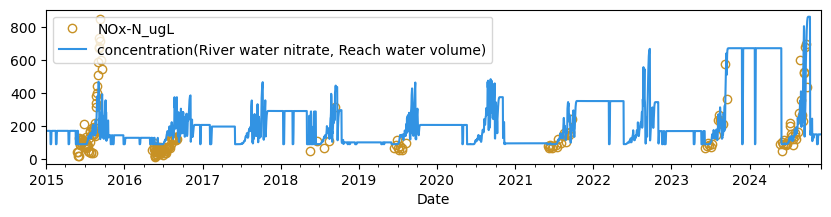

In [5]:
# Plot N simulation before autocalibration
mplt.plot_target(app, target, sl=slice('2015-01-01', optim_end))

In [6]:
# Run a minimizer to find a single best parameter set

# Extract stats from before the optimization
sim, obs = get_sim_obs(app)
ns_before = stat.nash_sutcliffe(sim, obs)
kg_before = stat.kling_gupta(sim, obs)

# Run the optimizer (This can take several minutes)
res_opt = opt.run_minimizer(app, params, set_params, get_sim_obs)

# Write the optimal parameters to the main app object
set_params(app, res_opt.params)
app.run()

# Extract stats after optimization
sim, obs = get_sim_obs(app)
ns_after = stat.nash_sutcliffe(sim, obs)
kg_after = stat.kling_gupta(sim, obs)

print("Nash-Sutcliffe efficiency: before: %g, after %g" % (ns_before, ns_after))
print("Kling-Gupta efficiency: before: %g, after %g" % (kg_before, kg_after))

Nash-Sutcliffe efficiency: before: 0.246428, after 0.538767
Kling-Gupta efficiency: before: 0.564869, after 0.623834


In [7]:
app.save_data_set(result_file)

<Axes: xlabel='Date'>

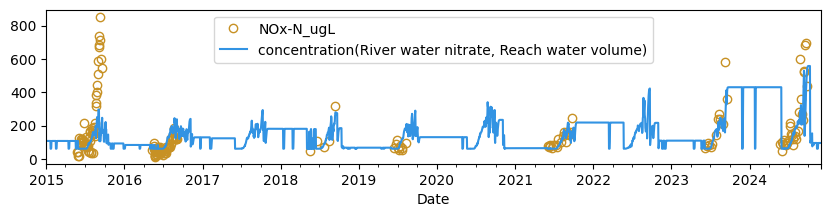

In [8]:
# Plot N simulation after autocalibration
mplt.plot_target(app, target, sl=slice('2015-01-01', optim_end))